# 🛒 Online Retail EDA: ventas, clientes y cancelaciones

## 🧭 Contexto de negocio

Una empresa minorista online quiere comprender su rendimiento comercial y sus cancelaciones antes de tomar decisiones. Este análisis explora registros de líneas de factura del dataset **Online Retail** de UCI.

## 🎯 Pregunta central

> ¿Qué patrones de ventas, clientes y cancelaciones debería conocer la empresa para mejorar sus decisiones comerciales?

## ⚠️ Alcance

El análisis es descriptivo. No demuestra causalidad y no calcula beneficios porque el dataset no contiene costes ni márgenes.

## 🗺️ Ruta del análisis

1. **Carga y estructura:** conocer el fichero y su unidad de análisis.
2. **Calidad de datos:** detectar nulos, duplicados y valores problemáticos.
3. **Valores nulos:** separar el alcance transaccional del alcance de clientes.
4. **Anomalías:** revisar operaciones extremas y posibles reversiones.
5. **Poblaciones:** definir qué registros entran en cada indicador.
6. **Distribuciones:** entender la dispersión y los valores extremos.
7. **Evolución temporal:** observar cambios mensuales sin atribuir causas no observadas.
8. **Cancelaciones por factura:** calcular una tasa comparable.
9. **Relaciones y volumen:** estudiar patrones descriptivos y peso de las líneas de alto volumen.
10. **Productos:** rankear productos físicos mediante ingresos netos.
11. **Países:** observar la concentración geográfica.
12. **Cancelaciones complementarias:** analizar evolución mensual y volumen absoluto.
13. **Clientes:** estudiar recurrencia solo cuando existe identificador.
14. **Síntesis:** traducir los hallazgos a decisiones y preguntas de negocio.

Cada sección explica qué calcula, para qué sirve y qué limitaciones tiene.

In [1]:
from pathlib import Path

print(list(Path("/content").glob("*")))

[PosixPath('/content/.config'), PosixPath('/content/Online Retail.xlsx'), PosixPath('/content/sample_data')]


In [2]:
# Configuramos el entorno y localizamos la fuente original del análisis.
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")

pd.set_option("display.max_columns", 50)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.2f}"
)

# El análisis utiliza directamente el Excel original.
# En Colab se usa /content; en ejecución local se usa dataset/.
CANDIDATE_PATHS = [
    Path("/content/Online Retail.xlsx"),
    Path("dataset/Online Retail.xlsx"),
    Path("../dataset/Online Retail.xlsx"),
]
DATA_PATH = next((path for path in CANDIDATE_PATHS if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "No se encontró Online Retail.xlsx. Súbelo a Colab o colócalo en dataset/."
    )

print(f"Archivo utilizado: {DATA_PATH.resolve()}")

df = pd.read_excel(DATA_PATH, engine="openpyxl")

Archivo utilizado: /content/Online Retail.xlsx


## 🔍 1. Carga y estructura

La unidad original es una **línea de factura**, no necesariamente un pedido completo. Una factura puede contener varias líneas de producto.

**Qué hacemos:** comprobamos de qué está compuesto el fichero y cuál es la unidad de análisis.

**Para qué sirve:** evita interpretar una línea de factura como si fuera necesariamente un pedido o un cliente completo.

In [3]:
# Cargamos el Excel original para conservar la trazabilidad de los datos.
df = pd.read_excel(DATA_PATH, engine="openpyxl")

print(f"Archivo utilizado: {DATA_PATH}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
display(df.head())
df.info()

Archivo utilizado: /content/Online Retail.xlsx
Filas: 541,909
Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
# Resumimos las variables para detectar rangos y valores atípicos iniciales.
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.00","25,900.00","573,585.00","1,114.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 💡 Primera lectura del resumen descriptivo

Este resumen todavía no responde por sí solo a la pregunta comercial, pero sí orienta la investigación:

- El fichero contiene **541.909 líneas**, **25.900 identificadores de factura**, **4.070 códigos de producto** y **38 países**. Por tanto, trabajamos con un volumen amplio y con varias dimensiones para comparar.
- `Quantity` tiene una mediana de **3 unidades**, una media de **9,55** y un máximo de **80.995**. La diferencia entre mediana y media sugiere una distribución sesgada por algunas líneas de gran volumen.
- `UnitPrice` tiene una mediana de **£2,08**, una media de **£4,61**, valores negativos y un máximo de **£38.970**. Esto indica que los precios requieren una revisión de calidad antes de usarlos en indicadores comerciales.
- `CustomerID` solo aparece en **406.829 de 541.909 filas**. Las métricas de clientes no pueden extenderse automáticamente a todo el dataset.
- Las fechas cubren desde diciembre de 2010 hasta diciembre de 2011, lo que permite estudiar evolución mensual, pero no comparar años.
- Reino Unido es el país más frecuente por número de líneas. Esto apunta a una posible concentración geográfica, aunque todavía debemos medirla por ingresos, facturas y tasas para no confundir volumen de registros con rendimiento comercial.

**Dirección de los siguientes análisis:** auditar los valores extremos y nulos, separar ventas de cancelaciones y calcular los indicadores por poblaciones explícitas. Estas observaciones son señales para investigar, no conclusiones de rentabilidad ni de causalidad.

**Conexión con el código:** esta primera lectura convierte el resumen estadístico en criterios para las siguientes secciones: auditar extremos, medir cobertura de clientes y definir denominadores antes de comparar resultados.

## 🧪 2. Auditoría de calidad de datos

Antes de calcular indicadores, revisamos nulos, duplicados, tipos, rangos y valores que pueden tener un significado operativo especial.

**Qué hacemos:** medimos tipos, nulos, duplicados, cantidades, precios y fechas problemáticas.

**Para qué sirve:** permite conocer qué riesgos pueden alterar los indicadores antes de calcular ventas o cancelaciones.

In [5]:
# Medimos la calidad de cada columna: tipo, nulos y valores distintos.
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=True),
})
display(quality.sort_values("missing_count", ascending=False))

print(f"Filas duplicadas exactas: {df.duplicated().sum():,}")

,dtype,missing_count,missing_pct,n_unique
CustomerID,float64,135080,24.93,4372
Description,object,1454,0.27,4223
StockCode,object,0,0.00,4070
InvoiceNo,object,0,0.00,25900
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
Country,object,0,0.00,38


Filas duplicadas exactas: 5,268


In [6]:
# Creamos una copia de trabajo; el fichero original no se modifica.
# Creamos una copia completa e independiente: no es un subset ni elimina filas.
# Así podemos limpiar nombres y añadir variables sin modificar el DataFrame original `df`.
data = df.copy()
data.columns = [column.strip() for column in data.columns]
# Convertimos la fecha para poder agrupar por mes, día y hora.
# Si una fecha no se puede interpretar, queda como nula y se contabiliza en la auditoría.
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")
# Regla observada en la fuente: las facturas cuyo identificador empieza por C se marcan como canceladas.
data["IsCancellation"] = data["InvoiceNo"].astype(str).str.startswith("C")
# Calculamos el valor registrado de cada línea; es ingreso, no beneficio.
data["Revenue"] = data["Quantity"] * data["UnitPrice"]

quality_cases = pd.DataFrame({
    "Caso": [
        "CustomerID ausente",
        "Description ausente",
        "Cantidad negativa",
        "Cantidad negativa sin factura C",
        "Factura C",
        "Precio cero",
        "Precio negativo",
        "Duplicado exacto",
        "Fecha no interpretada",
    ],
    "Filas": [
        int(data["CustomerID"].isna().sum()),
        int(data["Description"].isna().sum()),
        int((data["Quantity"] < 0).sum()),
        int(((data["Quantity"] < 0) & (~data["IsCancellation"])).sum()),
        int(data["IsCancellation"].sum()),
        int((data["UnitPrice"] == 0).sum()),
        int((data["UnitPrice"] < 0).sum()),
        int(data.duplicated().sum()),
        int(data["InvoiceDate"].isna().sum()),
    ],
})
display(quality_cases)

,Caso,Filas
0,CustomerID ausente,135080
1,Description ausente,1454
2,Cantidad negativa,10624
3,Cantidad negativa sin factura C,1336
4,Factura C,9288
5,Precio cero,2515
6,Precio negativo,2
7,Duplicado exacto,5268
8,Fecha no interpretada,0


### 💡 Lectura de calidad

La ausencia de `CustomerID` no es un detalle menor: limita el análisis de recurrencia y obliga a separar las métricas transaccionales de las métricas de cliente. Los duplicados, cantidades negativas y precios no positivos tampoco deben eliminarse automáticamente; pueden representar ajustes, reversiones o problemas de registro.

**Conexión con el código:** `data` es una copia de trabajo completa; la auditoría todavía no elimina ni corrige registros. Las decisiones de población se toman después y quedan separadas de la fuente original.

In [7]:
# Simulamos la deduplicación solo para medir su impacto, no para borrar datos.
deduplicated_data = data.drop_duplicates().copy()

duplicate_impact = pd.Series({
    "rows_before": len(data),
    "rows_after_exact_deduplication": len(deduplicated_data),
    "rows_removed": len(data) - len(deduplicated_data),
    "revenue_before": data["Revenue"].sum(),
    "revenue_after_exact_deduplication": deduplicated_data["Revenue"].sum(),
})
display(duplicate_impact)

,0
rows_before,"541,909.00"
rows_after_exact_deduplication,"536,641.00"
rows_removed,"5,268.00"
revenue_before,"9,747,747.93"
revenue_after_exact_deduplication,"9,726,006.95"


### ⚖️ Decisión sobre duplicados

Los duplicados exactos no se eliminan automáticamente del dataset original. Primero medimos su impacto y dejamos constancia de la diferencia. Las métricas principales se calcularán con una población explícitamente definida.

### 🧹 Decisiones de preparación

- `CustomerID` no se imputa: es un identificador, no una medición.
- Las filas sin cliente se conservan para productos, países e ingresos.
- Las métricas por cliente usan únicamente filas con `CustomerID`.
- Las facturas cuyo identificador empieza por `C` se consideran cancelaciones.
- Las cantidades negativas que no empiezan por `C` se conservan como señales de calidad o ajustes.
- Los duplicados se investigan antes de decidir si se eliminan.
- Los valores extremos no se borran automáticamente.

## 🕳️ 3. Valores nulos y alcance del análisis

No todos los nulos se tratan igual. En este dataset, `CustomerID` identifica a un cliente; no es una variable que podamos estimar de forma responsable. Imputarlo inventaría relaciones entre compras y clientes.

Por ello usamos dos vistas analíticas:

- **Vista transaccional:** conserva todas las filas para ventas, productos, países, cancelaciones y calidad de datos.
- **Vista de clientes:** contiene solo filas con `CustomerID` observado y se usa exclusivamente para métricas de clientes.

La segunda vista no es una corrección del dataset: es una restricción explícita del alcance del análisis.

**Qué hacemos:** conservamos todas las filas para el análisis transaccional y usamos solo `CustomerID` observado para el análisis de clientes.

**Para qué sirve:** evita inventar clientes y deja claro qué resultados cubren todo el dataset y cuáles tienen una cobertura más limitada.

`null_strategy` es una tabla de control: resume cuántas filas tienen identificador, qué porcentaje queda cubierto y cuántas descripciones faltan. Sirve para que cualquier métrica de clientes muestre también su cobertura.

In [8]:
# Separamos una vista completa y otra limitada a clientes identificados.
# Vista transaccional completa: conserva todas las filas para ventas, productos y calidad.
transaction_data = data.copy()
# Esta etiqueta solo sirve para mostrar gráficos; no sustituye el valor nulo original.
transaction_data["DescriptionForDisplay"] = transaction_data["Description"].fillna("Unknown description")

# Vista de clientes: aquí sí filtramos porque sin CustomerID no podemos atribuir una compra.
# No es una imputación ni una corrección del dataset; limita explícitamente el alcance del análisis.
customer_data = transaction_data.dropna(subset=["CustomerID"]).copy()
customer_data["CustomerID"] = customer_data["CustomerID"].astype("int64")

# Resumen de cobertura para dejar cuantificado qué parte del dataset permite análisis de clientes.
# El nombre `null_strategy` indica que estamos documentando la estrategia frente a los nulos.
null_strategy = pd.Series({
    "total_rows": len(transaction_data),
    "rows_with_customer_id": len(customer_data),
    "customer_id_coverage_pct": len(customer_data) / len(transaction_data) * 100,
    "rows_without_customer_id": transaction_data["CustomerID"].isna().sum(),
    "rows_without_description": transaction_data["Description"].isna().sum(),
})
display(null_strategy)

print("CustomerID no se imputa.")
print("Description solo recibe una etiqueta de presentación; el valor original permanece nulo.")

,0
total_rows,"541,909.00"
rows_with_customer_id,"406,829.00"
customer_id_coverage_pct,75.07
rows_without_customer_id,"135,080.00"
rows_without_description,"1,454.00"


CustomerID no se imputa.
Description solo recibe una etiqueta de presentación; el valor original permanece nulo.


## 🚨 4. Anomalías y operaciones revertidas

Un valor extremo puede ser una venta real, un ajuste, un error de registro o una operación posteriormente cancelada. Por eso no lo eliminamos sin investigar.

**Qué hacemos:** localizamos cantidades extremas y revisamos un caso concreto junto con su posible reversión.

**Para qué sirve:** evita que una operación excepcional distorsione rankings de productos, inventario o decisiones de compra.

El umbral `10_000` es un criterio práctico para localizar operaciones que merecen revisión. No significa que toda cantidad superior sea incorrecta ni que las inferiores sean automáticamente correctas.

In [9]:
# Buscamos líneas con cantidades excepcionalmente grandes para revisarlas.
# 10_000 es un umbral numérico de cribado, no texto ni una regla de eliminación.
# `abs()` permite detectar tanto cantidades positivas como negativas extremas.
# Lo usamos para revisar casos de alto impacto; las filas no se borran por superar el umbral.
extreme_rows = (
    data.loc[data["Quantity"].abs() >= 10_000,
             ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country", "Revenue"]]
    .sort_values("Quantity", key=lambda values: values.abs(), ascending=False)
)
display(extreme_rows)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,"16,446.00",United Kingdom,"-168,469.60"
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,"16,446.00",United Kingdom,"168,469.60"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,"12,346.00",United Kingdom,"77,183.60"
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,"12,346.00",United Kingdom,"-77,183.60"
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,"13,256.00",United Kingdom,0.00


### 🔎 Caso destacado: `PAPER CRAFT , LITTLE BIRDIE`

La revisión del valor extremo muestra una línea de `+80.995` unidades y otra de `-80.995` unidades para el mismo producto, cliente y precio, con 12 minutos de diferencia.

La interpretación prudente es que se trata de una operación registrada y posteriormente revertida o cancelada. No podemos determinar si fue una errata, una compra masiva cancelada o un ajuste administrativo, pero **no debemos presentar las 80.995 unidades como demanda efectiva**.

In [10]:
# Seguimos el caso extremo hasta comprobar su resultado neto.
# `StockCode` es el identificador del producto, por eso filtramos por código y no solo por descripción.
# `.eq("23843")` compara cada código con la cadena exacta "23843" y devuelve una máscara booleana.
# Elegimos 23843 porque aparece en las líneas extremas que acabamos de detectar.
paper_craft = data.loc[
    data["StockCode"].astype(str).eq("23843"),
    ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country", "Revenue"]
].sort_values("InvoiceDate")

display(paper_craft)
print("Cantidad neta del producto:", paper_craft["Quantity"].sum())
print("Ingresos netos del producto:", paper_craft["Revenue"].sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,"16,446.00",United Kingdom,"168,469.60"
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,"16,446.00",United Kingdom,"-168,469.60"


Cantidad neta del producto: 0
Ingresos netos del producto: 0.0


### 💡 Lectura de la operación extrema

Este caso no debe presentarse como una venta efectiva de 80.995 unidades. La reversión inmediata deja el resultado neto en cero. La implicación empresarial es que los rankings comerciales necesitan conciliación con cancelaciones y ajustes antes de utilizarse para inventario, compras o planificación.

### 💡 Decisión analítica

Presentaremos dos perspectivas cuando sea necesario:

- **Bruta:** líneas positivas registradas como ventas.
- **Neta:** ventas y líneas negativas consideradas conjuntamente.

Para rankings de producto utilizaremos la perspectiva neta, porque evita destacar operaciones completamente revertidas.

## 🧹 5. Poblaciones analíticas

**Qué hacemos:** construimos poblaciones separadas para ventas positivas, cancelaciones y cálculo neto.

**Para qué sirve:** permite comparar magnitudes con reglas explícitas, sin mezclar ventas registradas con cancelaciones o ajustes.

In [11]:
# Creamos dimensiones de calendario y poblaciones con reglas de negocio explícitas.
data["Year"] = data["InvoiceDate"].dt.year
data["Month"] = data["InvoiceDate"].dt.to_period("M").astype(str)
data["DayOfWeek"] = data["InvoiceDate"].dt.day_name()
data["Hour"] = data["InvoiceDate"].dt.hour

# Ventas brutas: líneas positivas no canceladas y con precio positivo.
gross_sales = data.loc[
    (~data["IsCancellation"])
    & (data["Quantity"] > 0)
    & (data["UnitPrice"] > 0)
].copy()

# Cancelaciones identificadas explícitamente por el prefijo C.
cancellations = data.loc[data["IsCancellation"]].copy()

# Para el análisis neto se incluyen movimientos con precio positivo,
# tanto positivos como negativos.
net_lines = data.loc[data["UnitPrice"] > 0].copy()

summary = pd.Series({
    "source_rows": len(data),
    "gross_sales_rows": len(gross_sales),
    "cancellation_rows": len(cancellations),
    "net_analysis_rows": len(net_lines),
    "gross_sales_revenue": gross_sales["Revenue"].sum(),
    "cancellation_value_abs": cancellations["Revenue"].abs().sum(),
    "net_revenue": net_lines["Revenue"].sum(),
})
display(summary)

,0
source_rows,"541,909.00"
gross_sales_rows,"530,104.00"
cancellation_rows,"9,288.00"
net_analysis_rows,"539,392.00"
gross_sales_revenue,"10,666,684.54"
cancellation_value_abs,"896,812.49"
net_revenue,"9,769,872.05"


## 📈 6. Distribuciones y valores extremos

Los outliers pueden ser errores, ajustes, compras inusuales o reversiones. Se visualizan y se investigan; no se eliminan solo por superar un umbral estadístico.

**Qué hacemos:** observamos cómo se distribuyen cantidades, precios e ingresos por línea, incluyendo valores extremos.

**Para qué sirve:** ayuda a decidir qué registros requieren revisión y evita eliminarlos automáticamente por ser poco frecuentes.

**Cómo leer los dos primeros gráficos:**

- El gráfico de `Quantity` cuenta líneas según las unidades registradas. Permite ver el tamaño habitual de las líneas y si unas pocas operaciones de volumen dominan la escala.
- El gráfico de `UnitPrice` cuenta líneas según su precio por unidad. Permite ver el rango de precios habitual y detectar precios extremos que podrían distorsionar los ingresos.

En ambos casos, el eje vertical representa número de líneas, no ingresos ni beneficios.

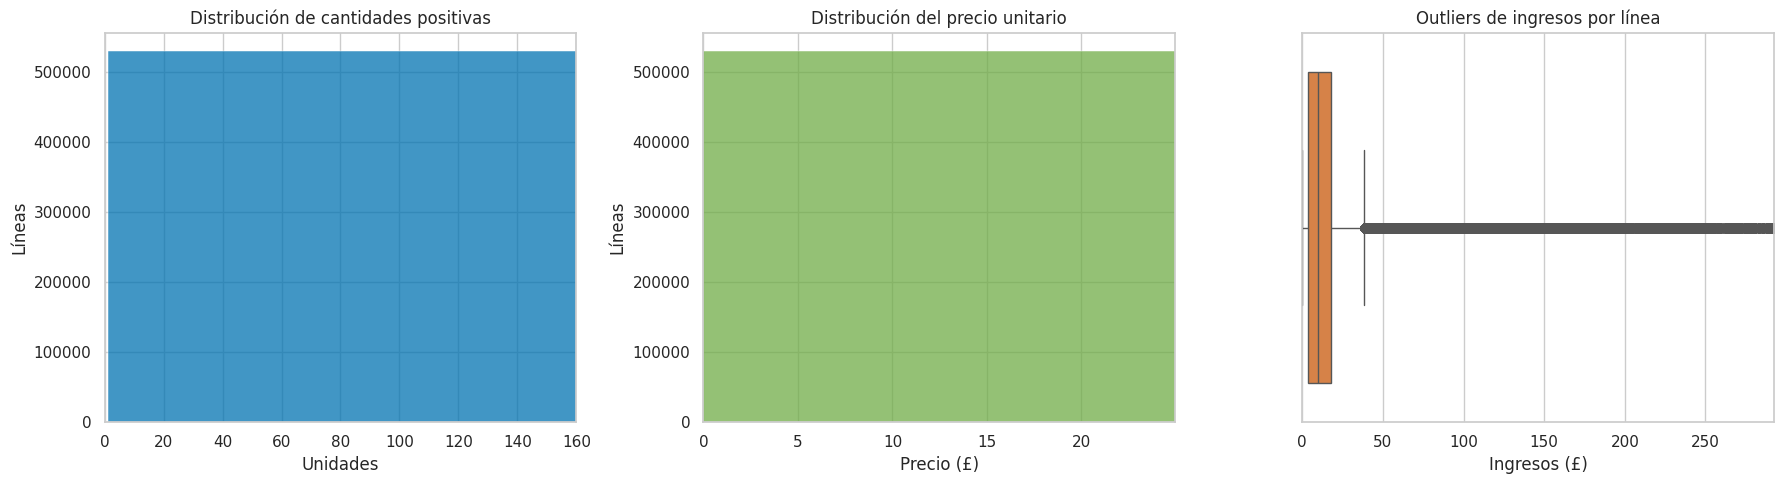

In [12]:
# Visualizamos las distribuciones; los límites del gráfico solo mejoran la lectura y no eliminan filas.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Primer gráfico: cada barra cuenta cuántas líneas de venta tienen un determinado número de unidades.
# Sirve para ver si las ventas suelen ser pequeñas y si existen colas de pedidos de gran volumen.
sns.histplot(data=gross_sales, x="Quantity", bins=80, ax=axes[0])
axes[0].set(title="Distribución de cantidades positivas", xlabel="Unidades", ylabel="Líneas")
# Mostramos hasta el percentil 99,5 para que los casos extremos no oculten la distribución habitual.
# Esto solo cambia la ventana del gráfico; no elimina registros ni cambia los cálculos.
axes[0].set_xlim(0, gross_sales["Quantity"].quantile(0.995))

# Segundo gráfico: cada barra cuenta cuántas líneas tienen un determinado precio unitario.
# Sirve para observar el nivel de precios habitual, su dispersión y posibles valores extremos.
sns.histplot(data=gross_sales, x="UnitPrice", bins=80, ax=axes[1], color="#70AD47")
axes[1].set(title="Distribución del precio unitario", xlabel="Precio (£)", ylabel="Líneas")
# De nuevo limitamos solo la visualización al percentil 99,5 para facilitar la lectura.
axes[1].set_xlim(0, gross_sales["UnitPrice"].quantile(0.995))

sns.boxplot(data=gross_sales, x="Revenue", ax=axes[2], color="#ED7D31")
axes[2].set(title="Outliers de ingresos por línea", xlabel="Ingresos (£)")
axes[2].set_xlim(0, gross_sales["Revenue"].quantile(0.995))
plt.tight_layout()
plt.show()

### 💡 Lectura de outliers

La distribución está muy sesgada: unas pocas líneas concentran cantidades o ingresos excepcionales. Estos registros deben revisarse como operaciones de alto impacto, pero no descartarse por defecto. Una decisión financiera necesitaría contrastarlos con pedidos, pagos e inventario.

## 📊 7. Evolución temporal

La tendencia se analiza con ventas brutas y cancelaciones separadas. Un aumento de ingresos no implica necesariamente un aumento de beneficio porque no conocemos costes ni márgenes.

**Qué hacemos:** comparamos ventas brutas, valor cancelado y número de facturas a lo largo del tiempo.

**Para qué sirve:** permite detectar meses de mayor actividad y formular hipótesis de estacionalidad sin atribuir causas que el dataset no contiene.

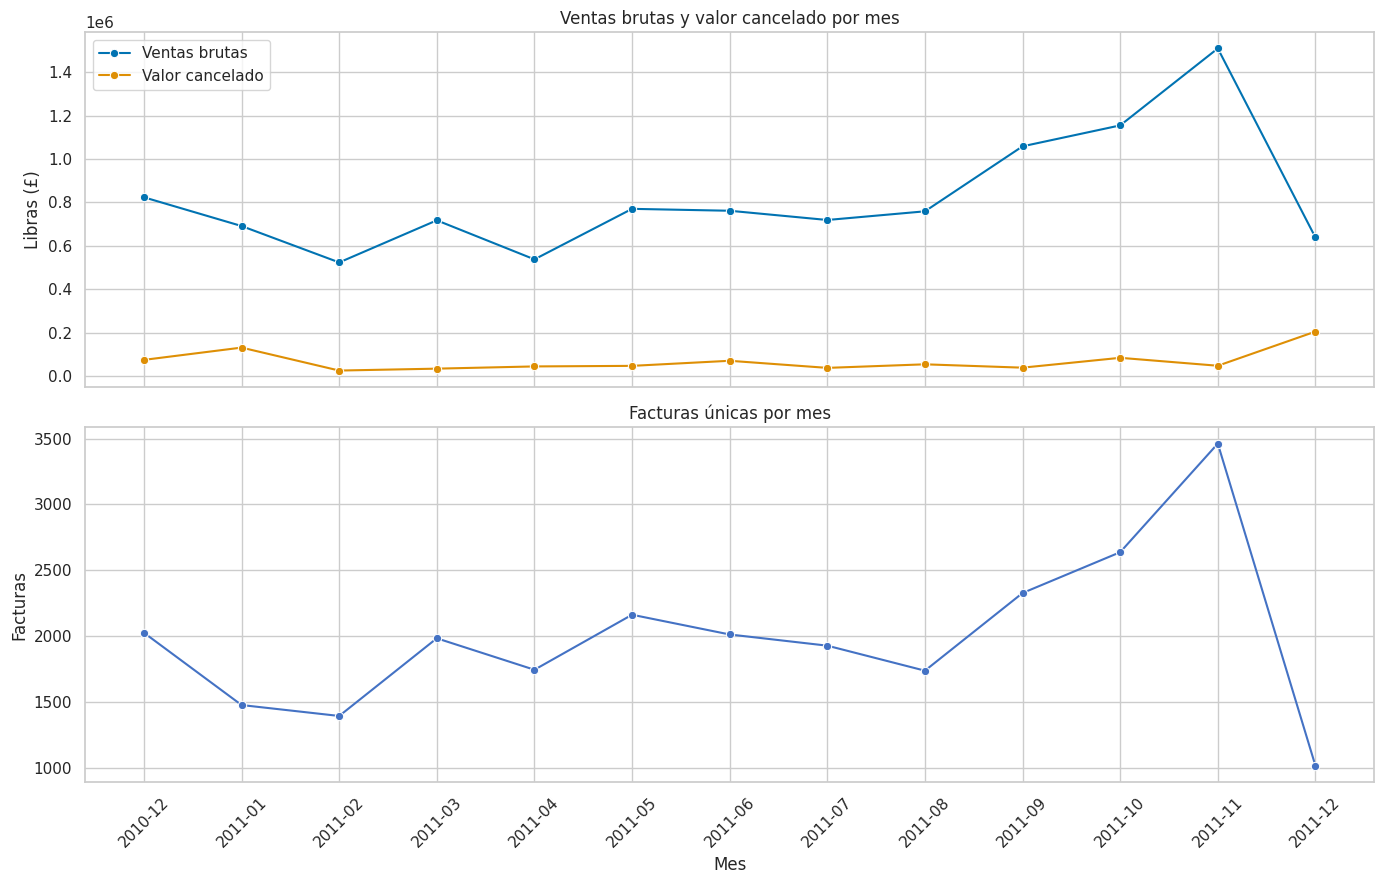

In [13]:
# Agregamos actividad mensual para separar ventas, cancelaciones y número de facturas.
monthly = (
    data.assign(
        GrossRevenue=np.where((~data["IsCancellation"]) & (data["Revenue"] > 0), data["Revenue"], 0),
        CancellationValue=np.where(data["IsCancellation"], data["Revenue"].abs(), 0),
    )
    .groupby("Month", as_index=False)
    .agg(
        GrossRevenue=("GrossRevenue", "sum"),
        CancellationValue=("CancellationValue", "sum"),
        Invoices=("InvoiceNo", "nunique"),
    )
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
sns.lineplot(data=monthly, x="Month", y="GrossRevenue", marker="o", ax=axes[0], label="Ventas brutas")
sns.lineplot(data=monthly, x="Month", y="CancellationValue", marker="o", ax=axes[0], label="Valor cancelado")
axes[0].set(title="Ventas brutas y valor cancelado por mes", xlabel="Mes", ylabel="Libras (£)")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(data=monthly, x="Month", y="Invoices", marker="o", ax=axes[1], color="#4472C4")
axes[1].set(title="Facturas únicas por mes", xlabel="Mes", ylabel="Facturas")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 💡 Lectura temporal

Noviembre de 2011 es el mes con mayor ingreso neto en esta extracción. Esto puede ser compatible con estacionalidad comercial, pero no podemos atribuirlo a una campaña o causa concreta porque el dataset no incluye campañas, costes ni inventario. Conviene usar el patrón como hipótesis para una investigación posterior.

## 📏 8. Cancelaciones: tasa por factura

Contar líneas canceladas puede sobrerrepresentar países o productos con más líneas. Calculamos también la tasa sobre facturas únicas, para comparar grupos con una base común.

**Qué hacemos:** calculamos la proporción de facturas canceladas y la comparamos por país usando un mínimo de 20 facturas.

**Para qué sirve:** una tasa con denominador es más comparable que contar únicamente líneas canceladas.

La **tasa por factura** responde a: “¿Qué proporción de las facturas únicas contiene al menos una línea marcada como cancelada?”. Es distinta del porcentaje de líneas canceladas y del valor monetario cancelado. Sirve para comparar países con una base común, aunque la regla de clasificación depende de que el prefijo `C` identifique correctamente la cancelación.

Tasa de facturas canceladas: 14.81%


,Country,TotalInvoices,CancelledInvoices,CancellationRatePct
20,Japan,28,9,32.14
19,Italy,55,17,30.91
33,Switzerland,74,20,27.03
14,Germany,603,146,24.21
32,Sweden,46,10,21.74
6,Channel Islands,33,7,21.21
26,Poland,24,5,20.83
10,EIRE,360,72,20.00
7,Cyprus,20,4,20.00
27,Portugal,71,13,18.31


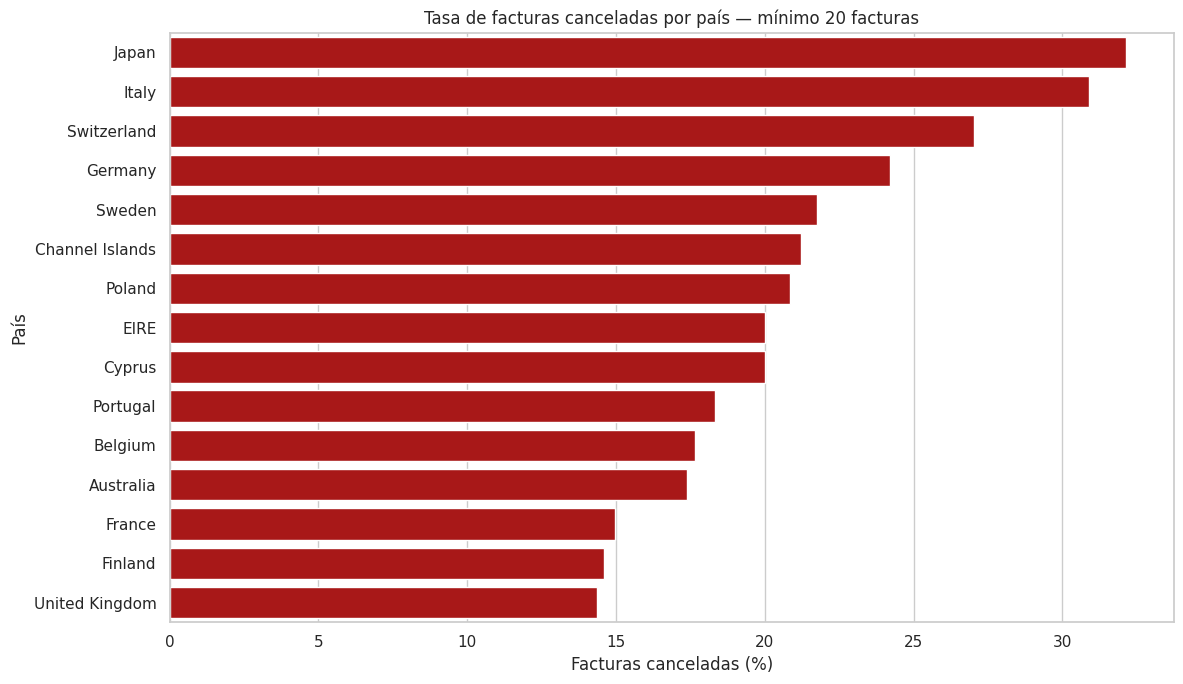

In [14]:
# Pasamos de líneas a facturas para calcular una tasa comparable de cancelación.
# Cambiamos temporalmente de líneas a facturas: una factura puede tener varias líneas.
# Así el denominador será el número de facturas únicas, no el número de filas.
invoice_status = (
    data.groupby("InvoiceNo", as_index=False)
    .agg(
        Country=("Country", "first"),
        # Si alguna línea de una factura está marcada como cancelación, la factura se clasifica como cancelada.
        IsCancellation=("IsCancellation", "max"),
        InvoiceValue=("Revenue", "sum"),
    )
)

invoice_status["Status"] = np.where(invoice_status["IsCancellation"], "Cancelada", "No cancelada")
# Tasa por factura = facturas canceladas / total de facturas únicas.
# No es el porcentaje de líneas canceladas ni el valor monetario cancelado.
overall_cancellation_rate = invoice_status["IsCancellation"].mean() * 100
print(f"Tasa de facturas canceladas: {overall_cancellation_rate:.2f}%")

country_cancellation = (
    invoice_status.groupby("Country", as_index=False)
    .agg(
        TotalInvoices=("InvoiceNo", "nunique"),
        CancelledInvoices=("IsCancellation", "sum"),
    )
)
country_cancellation["CancellationRatePct"] = (
    country_cancellation["CancelledInvoices"] / country_cancellation["TotalInvoices"] * 100
)
country_cancellation = country_cancellation.loc[country_cancellation["TotalInvoices"] >= 20]
display(country_cancellation.sort_values("CancellationRatePct", ascending=False).head(15))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=country_cancellation.sort_values("CancellationRatePct", ascending=False).head(15),
    x="CancellationRatePct",
    y="Country",
    color="#C00000",
)
plt.title("Tasa de facturas canceladas por país — mínimo 20 facturas")
plt.xlabel("Facturas canceladas (%)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

## 🔗 9. Relaciones y volumen de las líneas

La correlación ayuda a detectar relaciones descriptivas y posibles redundancias. No demuestra que una variable cause otra.

**Qué hacemos:** examinamos correlaciones descriptivas y comparamos el 10 % de líneas con mayor cantidad frente al resto.

**Para qué sirve:** ayuda a identificar el peso comercial de las operaciones de volumen, sin confundir ingresos con beneficios ni volumen con venta mayorista.

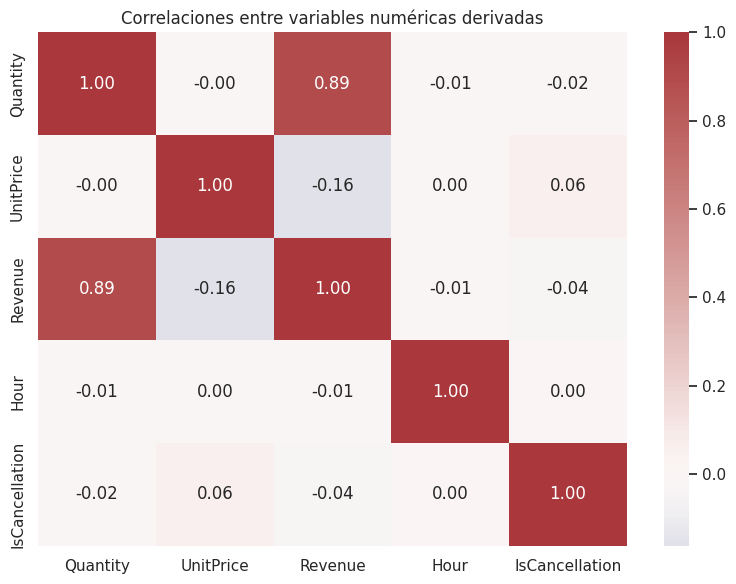

In [15]:
# Calculamos relaciones descriptivas entre variables; no son pruebas de causalidad.
correlation_data = data[["Quantity", "UnitPrice", "Revenue", "Hour"]].copy()
correlation_data["IsCancellation"] = data["IsCancellation"].astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_data.corr(numeric_only=True), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlaciones entre variables numéricas derivadas")
plt.tight_layout()
plt.show()

### 💡 Lectura del mapa de calor

La correlación entre `Quantity` y `Revenue` es alta, pero no permite concluir que la cantidad sea la causa de los ingresos: `Revenue` se calcula directamente como `Quantity × UnitPrice`. Tampoco podemos decir que la empresa obtenga más ganancias, porque no disponemos de costes ni márgenes.

La lectura defendible es que las operaciones de mayor volumen tienen capacidad de aportar mucho ingreso bruto. Debemos comprobar si también tienen un precio unitario diferente y si generan un valor neto material.

In [16]:
# Comparamos líneas de volumen alto y estándar sin llamarlas automáticamente mayoristas.
quantity_threshold = gross_sales["Quantity"].quantile(0.90)
gross_sales["VolumeSegment"] = np.where(
    gross_sales["Quantity"] >= quantity_threshold,
    "High-volume line",
    "Standard-volume line",
)

volume_comparison = (
    gross_sales.groupby("VolumeSegment", as_index=False)
    .agg(
        Lines=("InvoiceNo", "size"),
        Revenue=("Revenue", "sum"),
        RevenueShare=("Revenue", lambda values: values.sum() / gross_sales["Revenue"].sum() * 100),
        AverageQuantity=("Quantity", "mean"),
        AverageUnitPrice=("UnitPrice", "mean"),
        AverageLineRevenue=("Revenue", "mean"),
    )
)
display(volume_comparison)

,VolumeSegment,Lines,Revenue,RevenueShare,AverageQuantity,AverageUnitPrice,AverageLineRevenue
0,High-volume line,56363,"4,621,619.99",43.33,59.51,1.31,82.00
1,Standard-volume line,473741,"6,045,064.55",56.67,4.72,4.22,12.76


### 💡 Lectura de volumen

Las líneas del 10 % superior de cantidad representan aproximadamente el 43,3 % del ingreso bruto y tienen un precio unitario medio inferior al resto. Esto es compatible con pedidos de mayor volumen o una estrategia de precios por cantidad, pero no demuestra que sean operaciones mayoristas ni que sean más rentables.

## 📦 10. Productos: rendimiento neto

Las líneas de portes, descuentos, muestras y ajustes no se interpretan como productos físicos. Se excluyen del ranking de productos, pero se conservan en el análisis de calidad.

**Qué hacemos:** excluimos del ranking los códigos identificados como portes, descuentos, muestras o ajustes, y calculamos ingresos netos por producto físico.

**Para qué sirve:** ofrece un ranking comercial más útil sin borrar esos movimientos del análisis de calidad.

,StockCode,Description,NetRevenue,NetQuantity,Invoices
1265,22423,REGENCY CAKESTAND 3 TIER,"164,762.19",13022,2168
2674,47566,PARTY BUNTING,"98,302.98",18018,1705
3787,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"97,715.99",35021,2231
3775,85099B,JUMBO BAG RED RETROSPOT,"92,356.03",47359,2132
1954,23084,RABBIT NIGHT LIGHT,"66,756.59",30680,1009
947,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"63,791.94",18902,1170
2882,84879,ASSORTED COLOUR BIRD ORNAMENT,"58,959.73",36381,1467
2743,79321,CHILLI LIGHTS,"53,768.06",10226,667
2210,23298,SPOTTY BUNTING,"42,065.32",8217,1152
1232,22386,JUMBO BAG PINK POLKADOT,"41,619.66",21009,1231


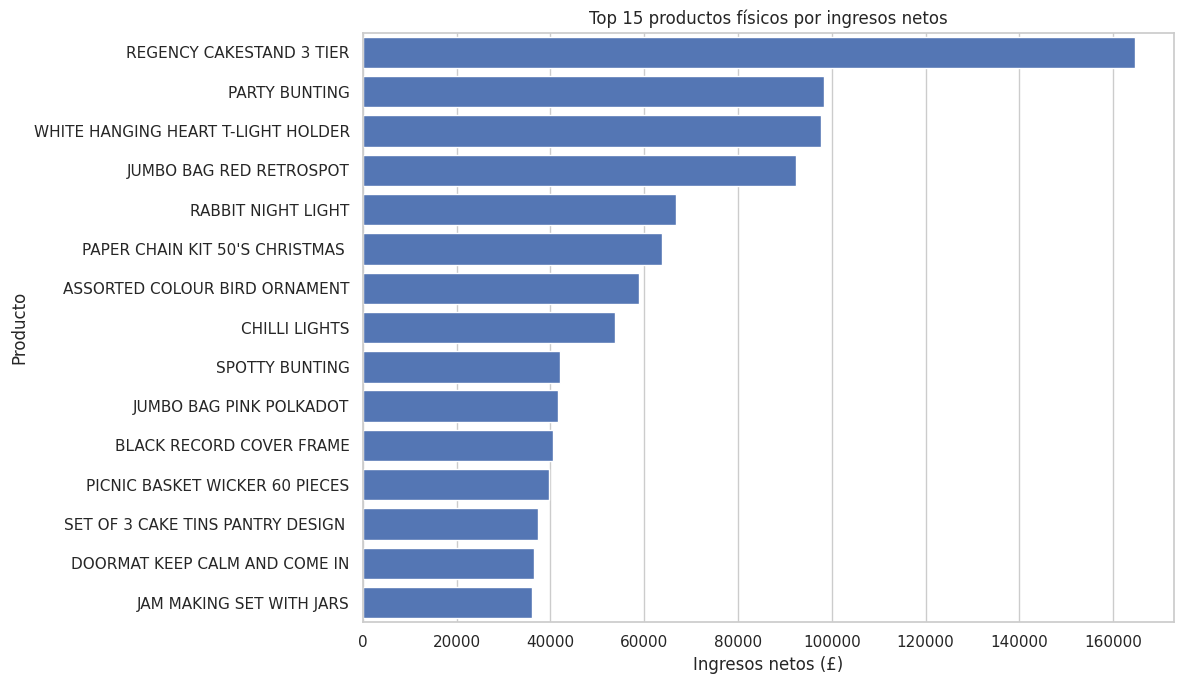

In [17]:
# Separamos conceptos operativos de productos físicos solo para el ranking de productos.
non_merchandise_codes = {
    "AMAZONFEE", "B", "BANK CHARGES", "C2", "CRUK", "D", "DOT", "M", "POST", "S",
    "gift_0001_10", "gift_0001_20", "gift_0001_30", "gift_0001_40", "gift_0001_50",
}
merchandise_net = net_lines.loc[~net_lines["StockCode"].isin(non_merchandise_codes)].copy()

top_products_net = (
    merchandise_net.groupby(["StockCode", "Description"], dropna=False, as_index=False)
    .agg(NetRevenue=("Revenue", "sum"), NetQuantity=("Quantity", "sum"), Invoices=("InvoiceNo", "nunique"))
    .sort_values("NetRevenue", ascending=False)
    .head(15)
)

display(top_products_net.head(10))

plt.figure(figsize=(12, 7))
sns.barplot(data=top_products_net, y="Description", x="NetRevenue", color="#4472C4")
plt.title("Top 15 productos físicos por ingresos netos")
plt.xlabel("Ingresos netos (£)")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

### 💡 Lectura de productos

El ranking neto evita que una operación completamente revertida aparezca como un producto estrella. Los productos líderes muestran contribución de ingresos, no rentabilidad: faltan costes, descuentos completos, devoluciones logísticas y margen.

## 🌍 11. Países

El análisis por país muestra contribución comercial, pero no permite calcular rentabilidad porque faltan costes de envío, adquisición y operación.

**Qué hacemos:** agregamos ingresos, unidades y facturas por país.

**Para qué sirve:** muestra la concentración geográfica de la actividad y orienta preguntas posteriores sobre pedidos, clientes y logística.

,Country,NetRevenue,NetQuantity,Invoices
36,United Kingdom,"8,209,930.48",4399357,21391
24,Netherlands,"284,661.54",199552,100
10,EIRE,"263,276.82",142363,360
14,Germany,"221,698.21",117446,603
13,France,"197,403.90",110479,461
0,Australia,"137,077.27",83345,69
33,Switzerland,"56,385.35",30324,74
31,Spain,"54,774.58",26813,105
3,Belgium,"40,910.96",23152,119
32,Sweden,"36,595.91",35637,46


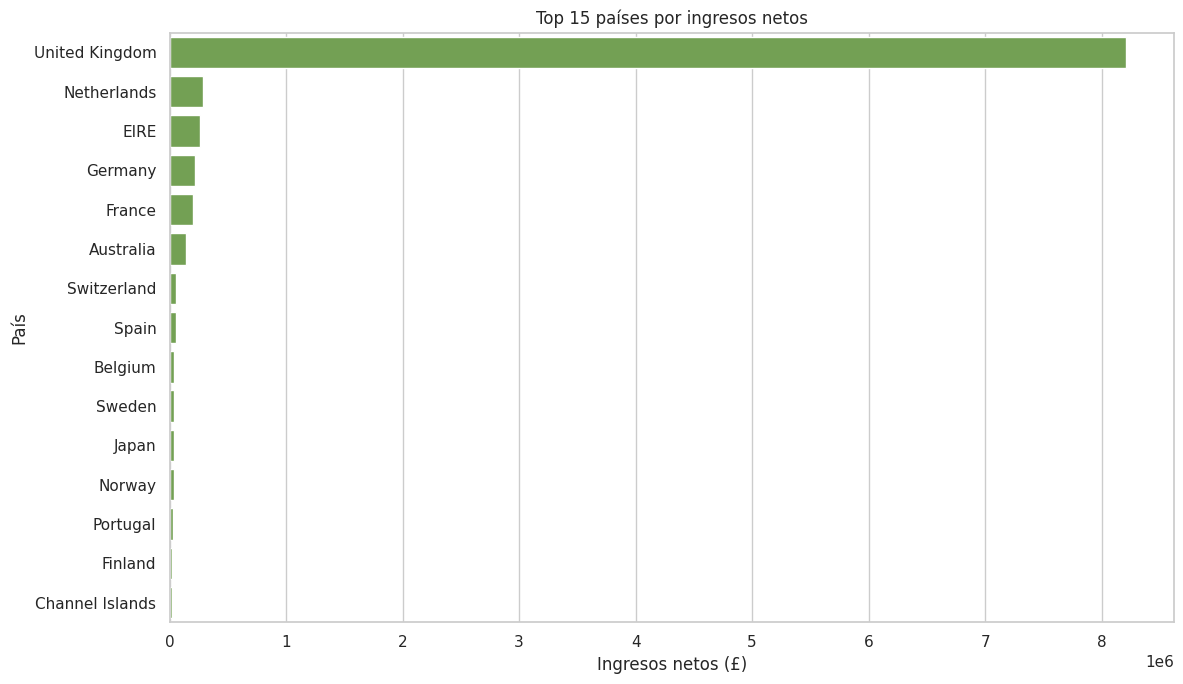

In [18]:
# Agregamos los ingresos netos por país para observar la concentración geográfica.
country_net = (
    net_lines.groupby("Country", as_index=False)
    .agg(NetRevenue=("Revenue", "sum"), NetQuantity=("Quantity", "sum"), Invoices=("InvoiceNo", "nunique"))
    .sort_values("NetRevenue", ascending=False)
)

display(country_net.head(10))

plt.figure(figsize=(12, 7))
sns.barplot(data=country_net.head(15), y="Country", x="NetRevenue", color="#70AD47")
plt.title("Top 15 países por ingresos netos")
plt.xlabel("Ingresos netos (£)")
plt.ylabel("País")
plt.tight_layout()
plt.show()

### 💡 Lectura geográfica

Reino Unido concentra aproximadamente el 84 % de los ingresos netos. Esto puede reflejar el mercado principal de la empresa y también una mayor base de pedidos. Las comparaciones internacionales deben incorporar número de pedidos, clientes, ticket medio y costes logísticos.

## ↩️ 12. Cancelaciones: evolución y concentración

Las cancelaciones se analizan por separado. Una cancelación puede reflejar devolución, error administrativo o reversión; el dataset no permite conocer por sí solo la causa.

**Qué hacemos:** complementamos la tasa por factura con la evolución mensual y el volumen de líneas canceladas por país.

**Para qué sirve:** distingue el tamaño absoluto del fenómeno de su tasa relativa; ambos indicadores responden a preguntas distintas.

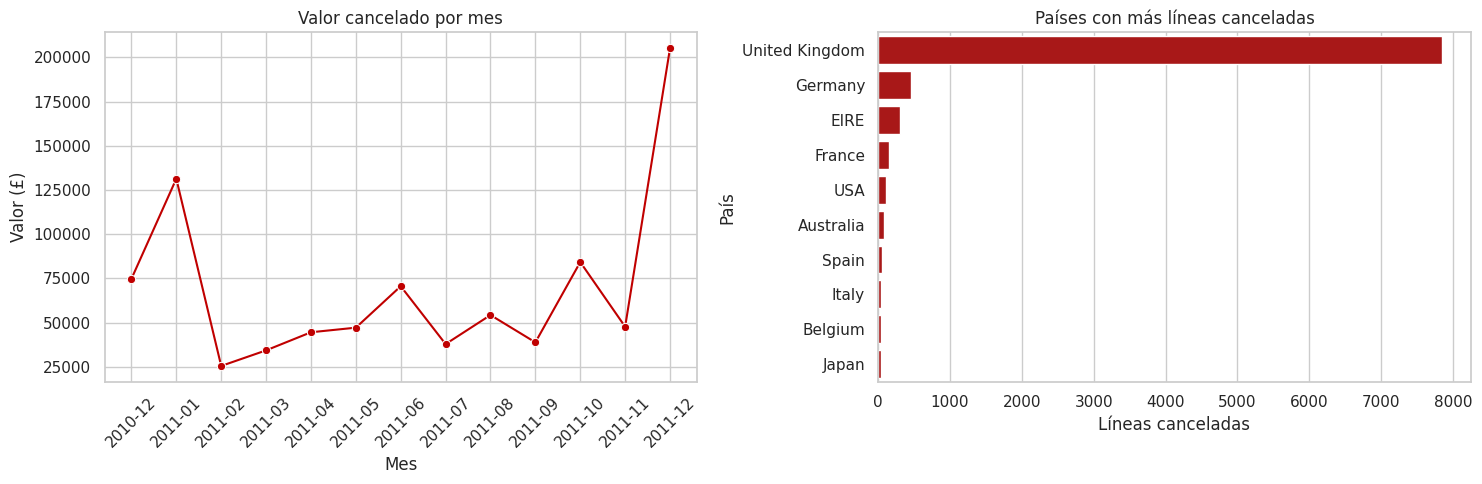

In [19]:
# Agregamos actividad mensual para separar ventas, cancelaciones y número de facturas.
cancellation_monthly = (
    cancellations.groupby("Month", as_index=False)
    .agg(
        CancellationLines=("InvoiceNo", "size"),
        CancellationInvoices=("InvoiceNo", "nunique"),
        CancellationValue=("Revenue", lambda values: values.abs().sum()),
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=cancellation_monthly, x="Month", y="CancellationValue", marker="o", ax=axes[0], color="#C00000")
axes[0].set(title="Valor cancelado por mes", xlabel="Mes", ylabel="Valor (£)")
axes[0].tick_params(axis="x", rotation=45)

cancelled_countries = cancellations["Country"].value_counts().head(10).rename_axis("Country").reset_index(name="CancellationLines")
sns.barplot(data=cancelled_countries, x="CancellationLines", y="Country", ax=axes[1], color="#C00000")
axes[1].set(title="Países con más líneas canceladas", xlabel="Líneas canceladas", ylabel="País")
plt.tight_layout()
plt.show()

### 💡 Lectura de cancelaciones

La tasa global de facturas canceladas es aproximadamente del 14,81 %. Las tasas por país son útiles solo con un número mínimo de facturas. Con un denominador pequeño, una sola cancelación cambia mucho el porcentaje: por ejemplo, 1 cancelación de 2 facturas produce un 50 %, pero no representa necesariamente un patrón estable. Por eso aplicamos un mínimo de 20 facturas; es un filtro de comparabilidad, no una prueba de que los países excluidos no tengan cancelaciones. La cancelación debe tratarse como indicador de seguimiento, no como prueba de un problema causal.

## 👥 13. Clientes

Las conclusiones de esta sección se limitan a las transacciones con `CustomerID` disponible. No se imputa el identificador.

**Qué hacemos:** agrupamos las ventas de clientes con `CustomerID` observado y distinguimos compras únicas de clientes recurrentes.

**Para qué sirve:** ayuda a estudiar retención y concentración de valor, indicando siempre que no cubre las filas sin identificador.

In [20]:
# Agrupamos únicamente clientes con identificador observado para medir recurrencia.
customer_sales = (
    gross_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID", as_index=False)
    .agg(
        GrossRevenue=("Revenue", "sum"),
        Invoices=("InvoiceNo", "nunique"),
        Products=("StockCode", "nunique"),
    )
)
customer_sales["CustomerType"] = np.where(customer_sales["Invoices"] > 1, "Recurrente", "Una sola compra")

customer_summary = customer_sales.groupby("CustomerType").agg(
    Customers=("CustomerID", "nunique"),
    GrossRevenue=("GrossRevenue", "sum"),
    AverageRevenue=("GrossRevenue", "mean"),
    AverageInvoices=("Invoices", "mean"),
)
display(customer_summary)

,Customers,GrossRevenue,AverageRevenue,AverageInvoices
CustomerType,,,,
Recurrente,2845,"8,295,096.17","2,915.68",5.99
Una sola compra,1493,"616,311.73",412.80,1.00


### 💡 Lectura de clientes

Los clientes recurrentes concentran la mayor parte de los ingresos identificables. Esto sugiere que la retención merece atención, pero no demuestra que una acción concreta produzca recurrencia. Además, la conclusión solo cubre clientes con `CustomerID` registrado.

## 💡 14. Síntesis de hallazgos

### 1. La calidad de los datos condiciona el análisis

El 24,93 % de las filas no tiene `CustomerID` y existen 5.268 duplicados exactos. Además, hay cantidades negativas que no corresponden a facturas con prefijo `C`, precios cero y ajustes con precios negativos. Por tanto, una única métrica sin explicar la población analizada sería engañosa.

### 2. Las cancelaciones tienen un impacto material

Las ventas brutas positivas suman aproximadamente **£10,67 millones**, mientras que el valor absoluto de las líneas identificadas como cancelación suma aproximadamente **£896.812**. El 14,81 % de las facturas únicas aparece marcado como cancelado. Esto justifica controlar cancelaciones y reversiones como un indicador comercial separado.

### 3. El ranking bruto puede ocultar operaciones revertidas

`PAPER CRAFT , LITTLE BIRDIE` aparece con 80.995 unidades positivas, pero existe una reversión por la misma cantidad 12 minutos después. Su cantidad e ingresos netos son cero. Este caso demuestra que el ranking debe utilizar ingresos netos o, como mínimo, revisar valores extremos antes de tomar decisiones.

### 4. La facturación está muy concentrada geográficamente

Reino Unido representa aproximadamente el 84 % de los ingresos netos calculados. Las comparaciones internacionales deben utilizar tasas y denominadores, no solo volumen absoluto.

### 5. Los clientes recurrentes concentran el valor identificado

Entre las filas con `CustomerID`, se identifican 4.338 clientes. Los 2.845 clientes recurrentes representan aproximadamente el 65,6 % de los clientes identificados y generan alrededor del 93,1 % de los ingresos brutos de esa población. Este patrón sugiere una oportunidad de estudiar retención, aunque no demuestra que la recurrencia sea causada por una acción concreta.

### 6. Las líneas de alto volumen son relevantes, pero no demuestran venta mayorista

El 10 % superior de líneas positivas por cantidad representa aproximadamente el 43,3 % del ingreso bruto y tiene un precio unitario medio inferior al resto. Esto es compatible con pedidos de mayor volumen o precios por cantidad, pero el dataset no identifica operaciones mayoristas ni permite medir su rentabilidad.

### Recomendaciones

- Crear un control de conciliación para cancelaciones y operaciones de importe o cantidad extrema.
- Separar productos físicos de portes, descuentos, muestras y ajustes en los indicadores comerciales.
- Mejorar la captura de `CustomerID` para ampliar la fiabilidad de las métricas de cliente.
- Evaluar mercados internacionales con tasas de cancelación y métricas por pedido, no solo con ingresos totales.
- Analizar la recurrencia con información adicional de margen, coste de adquisición y logística antes de tomar decisiones de inversión.

Estas conclusiones son descriptivas y deben validarse con costes, motivos de cancelación y reglas operativas del negocio.

**Qué hacemos:** reunimos los patrones observados, sus posibles implicaciones y sus límites.

**Para qué sirve:** transforma el análisis descriptivo en preguntas y decisiones empresariales verificables, sin presentar hipótesis como hechos.

## ⚠️ Limitaciones

- El dataset no contiene costes, márgenes ni gastos logísticos.
- `CustomerID` falta en una parte relevante de las filas.
- Algunas líneas representan portes, descuentos, muestras o ajustes.
- Las cancelaciones no incluyen el motivo.
- Los patrones descriptivos no prueban causalidad.
- La unidad original es una línea de factura, no necesariamente un pedido completo.